In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib import rc
import matplotlib as mpl
from scipy.integrate import quad
from scipy.optimize import curve_fit
from mlpoppyns.simulator.config_simulator import cfg
import mlpoppyns.simulator.basics.constants as const
import mlpoppyns.simulator.multiband_emission.emission_radio as er
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

import matplotlib.ticker as ticker
from matplotlib.colors import LogNorm
import matplotlib.gridspec as gridspec

import utilities.plot_settings
from matplotlib.ticker import FixedLocator

import mlpoppyns.simulator.magneto_rotational_physics.magneto_rotational_evolution as mre
import mlpoppyns.simulator.magneto_rotational_physics.period_derivative as pdv

from scipy.integrate import odeint
plt.rcParams['text.usetex'] = True


## Changes needed for the constant magnetic field case: 
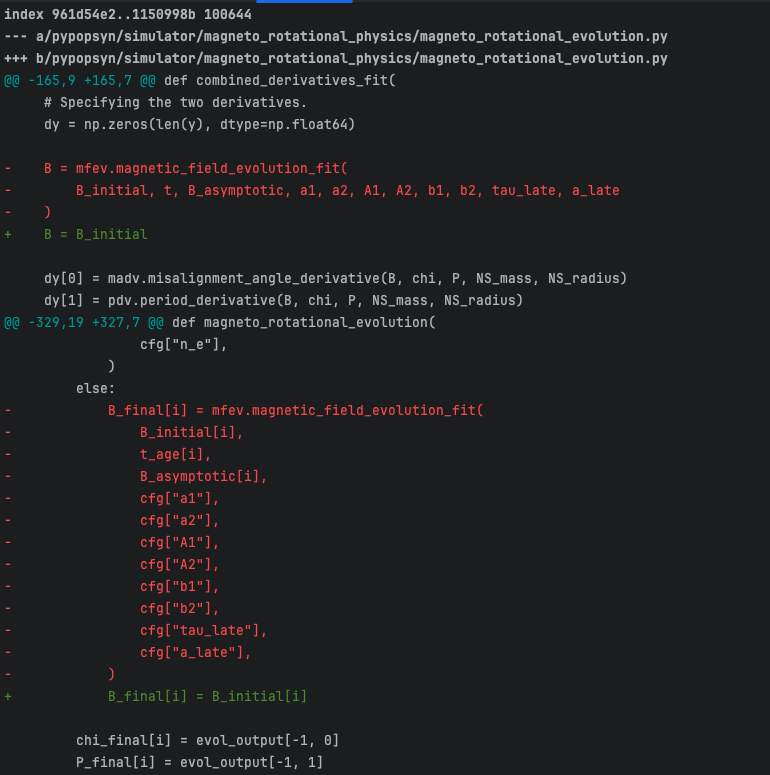

In [ ]:
cfg['magrot_time_step_log10'] == 1e-4
P_initial_list = np.array([0.01,0.1])
t_list = []
tau_c_list = []
constant = False
pdot_jump = False

for period in P_initial_list: 
    cfg["t_age_maxes[0]"] = 2e6
    
    a1 = cfg["a1"]
    a2 = cfg["a2"]
    A1 = cfg["A1"]
    A2 = cfg["A2"]
    b1 = cfg["b1"]
    b2 = cfg["b2"]
    tau_late = cfg["tau_late"]
    
    a_late = cfg["a_late"]
    
    # Set the initial conditions.
    log_B0 = np.array([12, 13, 14, 15])
    B_initial = 10**log_B0
    chi_initial = np.array([0.8 * np.pi / 2, 0.8 * np.pi / 2, 0.8 * np.pi / 2, 0.8 * np.pi / 2])
    P_initial = np.array([period, period, period, period])
    t_age = np.array([cfg["t_age_maxes[0]"], cfg["t_age_maxes[0]"], cfg["t_age_maxes[0]"], cfg["t_age_maxes[0]"]])
    
    cfg["save_magrot_evolution"] = True
    
    # Create a colormap and normalize it.
    cmap = plt.cm.viridis
    norm = Normalize(vmin=min(log_B0), vmax=max(log_B0))    
    P_dot_initial = np.zeros(len(log_B0))
    
    for i in range(len(P_dot_initial)):
        P_dot_initial[i] = (
            pdv.period_derivative(
                B_initial[i], chi_initial[i], P_initial[i], cfg["NS_mass"], cfg["NS_radius"]
            )
            / const.YR_TO_S
        )
    print(P_dot_initial)
    t = [np.array([]) for _ in range(len(log_B0))]
    B = [np.array([]) for _ in range(len(log_B0))]
    chi = [np.array([]) for _ in range(len(log_B0))]
    P = [np.array([]) for _ in range(len(log_B0))]
    P_dot = [np.array([]) for _ in range(len(log_B0))]
    
    B_final, chi_final, P_final, evolution_dictionary = mre.magneto_rotational_evolution(B_initial, chi_initial, P_initial, t_age)
    
    print(evolution_dictionary)
    
    for i in range(len(log_B0)):
        t[i] = evolution_dictionary[i]["t"]
        if constant: 
            B[i] = np.ones(len(evolution_dictionary[i]["B(t)"]))*B_initial[i]
        else:
            B[i] = evolution_dictionary[i]["B(t)"]
        chi[i] = evolution_dictionary[i]["chi(t)"]
        P[i] = evolution_dictionary[i]["P(t)"]
        
    period_derivative_vect = np.vectorize(pdv.period_derivative)
    
    for i in range(len(log_B0)):
        P_dot[i] = period_derivative_vect(B[i], chi[i], P[i], cfg["NS_mass"], cfg["NS_radius"]) / const.YR_TO_S
        
    t_list.append(t)    
    tau_c_list.append(np.array(P) / (2*np.array(P_dot)) / const.YR_TO_S)



In [ ]:
plt.rcParams['text.usetex'] = True

fig = plt.figure(figsize=(10, 8))

# --- Create GridSpec conditionally based on whether colorbar is needed ---
if not constant:
    gs = gridspec.GridSpec(2, 2, width_ratios=[20, 1])  # Leave room for colorbar
    axes = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])]
    #cax = fig.add_subplot(gs[:, 1])  # Colorbar axis
else:
    gs = gridspec.GridSpec(2, 1)  # No colorbar column
    axes = [fig.add_subplot(gs[0]), fig.add_subplot(gs[1])]

# --- Figure title and save path ---
axpos = axes[0].get_position()
x_center = (axpos.x0 + axpos.x1) / 2

if pdot_jump:
    fig.suptitle(r'$\dot{P}$\rm\ change', fontsize=24, x=x_center)
    save_fig = '/Users/celsapardoaraujo/Documents/data/magnetar-br/plots/charact_vs_real_age_ppdot_ppdot_jump.pdf'
elif constant:
    fig.suptitle(r'\rm Constant magnetic field', fontsize=24, x=x_center)
    save_fig = '/Users/celsapardoaraujo/Documents/data/magnetar-br/plots/charact_vs_real_age_ppdot_ppdot_constant_mag.pdf'
else:
    fig.suptitle(r'\rm Decaying magnetic field', fontsize=24, x=x_center)
    save_fig = '/Users/celsapardoaraujo/Documents/data/magnetar-br/plots/charact_vs_real_age_ppdot_ppdot_decaying_mag.pdf'


# --- Setup color normalization using B_initial (logarithmic scale) ---
norm = LogNorm(vmin=min(B_initial), vmax=max(B_initial))
sm = ScalarMappable(cmap=cmap, norm=norm)

# --- Top panel ---
for i in range(len(B_initial)):
    axes[0].plot(
        t_list[0][i],
        tau_c_list[0][i] / t_list[0][i],
        "-",
        color=cmap(norm(B_initial[i])),
        lw=3,
        label=fr"$B_0 = 10^{{{int(np.log10(B_initial[i]))}}}\,\rm G$"

    )

axes[0].set_xlim(1.0, 2e6)
axes[0].set_ylim(1e-5, 1e6)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].grid(True)
axes[0].tick_params(labelbottom=False)
axes[0].set_ylabel(r"$\tau_c/t$")

# --- Bottom panel ---
for i in range(len(B_initial)):
    axes[1].plot(
        t_list[1][i],
        tau_c_list[1][i] / t_list[1][i],
        "-",
        color=cmap(norm(B_initial[i])),
        lw=3
    )

axes[1].set_xlim(1.0, 2e6)
axes[1].set_ylim(1e-5, 1e6)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].grid(True)
axes[1].set_xlabel(r"$t$ [yr]")
axes[1].set_ylabel(r"$\tau_c/t$")

# --- Labels for constant case ---
if not pdot_jump and constant:
    axes[0].text(
        0.8, 0.95, r"$P_0 = 0.01 \rm s$", transform=axes[0].transAxes,
        fontsize=24, verticalalignment='top',
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="black")
    )
    axes[1].text(
        0.82, 0.95, r"$P_0 = 0.1 \rm s$", transform=axes[1].transAxes,
        fontsize=24, verticalalignment='top',
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="black")
    )

# --- Ticks ---
x_ticks = [1e0, 1e2, 1e4, 1e6]
y_ticks = [1e-3, 1e0, 1e3, 1e6]

for ax in axes:
    ax.set_xticks(x_ticks)
    ax.set_yticks(y_ticks)
    ax.set_xticklabels([f"$10^{{{int(np.log10(t))}}}$" for t in x_ticks])
    ax.set_yticklabels([f"$10^{{{int(np.log10(t))}}}$" for t in y_ticks])
    if not constant or pdot_jump:
        ax.tick_params(axis='y', labelleft=False)
        ax.set_ylabel("")

# --- Add colorbar (logarithmic scale in B0) ---
#if not constant:
    #cbar = fig.colorbar(sm, cax=cax)
    #cbar.set_label(r"$B_0 \, [{\rm G}]$")
    # Optional: set log ticks manually if you want them neat
    #cbar.ax.yaxis.set_major_formatter(   ticker.FuncFormatter(lambda y, _: f"$10^{{{int(np.log10(y))}}}$"))
axes[0].legend(loc="best", fontsize=17)
# --- Save and show ---
plt.savefig(save_fig, bbox_inches='tight')
plt.show()


In [ ]:
B_initial

In [ ]:
log_B0

In [ ]:
cfg['magrot_time_step_log10']